In [1]:
import numpy as np
import pandas as pd 
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

import os, random, time, csv

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import torch.optim as optim

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.preprocessing import label_binarize

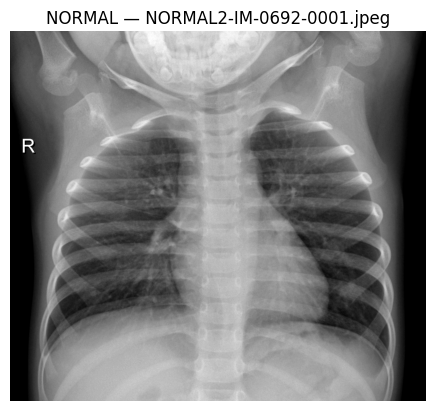

✅ Chemin local : chest_xray\train\NORMAL\NORMAL2-IM-0692-0001.jpeg


In [2]:
# ✅ Remplace ce chemin par le chemin complet vers ton dossier local
normal_dir = Path("chest_xray/train/NORMAL")

# Liste des fichiers images
image_files = list(normal_dir.glob("*.jpg")) + list(normal_dir.glob("*.jpeg")) + list(normal_dir.glob("*.png"))

# Vérification
if not image_files:
    print("❌ Aucun fichier image trouvé dans ce dossier.")
else:
    # Choisir une image aléatoirement
    p = random.choice(image_files)
    img = Image.open(p)

    # Affichage
    plt.imshow(img, cmap='gray')
    plt.title(f"NORMAL — {p.name}")
    plt.axis("off")
    plt.show()
    print("✅ Chemin local :", p)


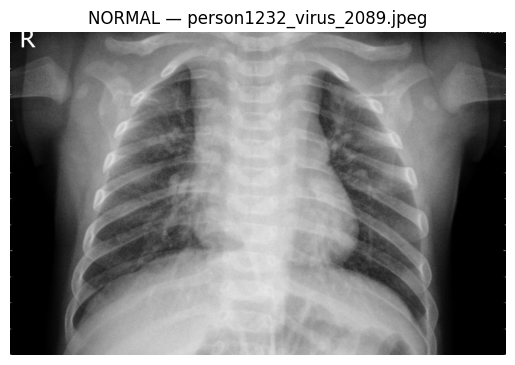

✅ Chemin local : chest_xray\train\PNEUMONIA\person1232_virus_2089.jpeg


In [3]:
# ✅ Remplace ce chemin par le chemin complet vers ton dossier local
normal_dir = Path("chest_xray/train/PNEUMONIA")

# Liste des fichiers images
image_files = list(normal_dir.glob("*.jpg")) + list(normal_dir.glob("*.jpeg")) + list(normal_dir.glob("*.png"))

# Vérification
if not image_files:
    print("❌ Aucun fichier image trouvé dans ce dossier.")
else:
    # Choisir une image aléatoirement
    p = random.choice(image_files)
    img = Image.open(p)

    # Affichage
    plt.imshow(img, cmap='gray')
    plt.title(f"NORMAL — {p.name}")
    plt.axis("off")
    plt.show()
    print("✅ Chemin local :", p)

In [4]:
# Seed / device
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


In [5]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

CUDA available: False
Device name: CPU only


In [6]:
# ✅ Chemin vers le dossier local où tu as extrait les données
# Remplace-le si nécessaire
DATA_DIR = Path("chest_xray")  # par exemple: "C:/Users/Mohammed/Documents/chest_xray"

# Dossiers des images
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR   = DATA_DIR / "val"
TEST_DIR  = DATA_DIR / "test"

# Dossiers de sortie (seront créés automatiquement)
OUT_DIR = Path("./results")
OUT_DIR.mkdir(exist_ok=True, parents=True)

MODEL_DIR = Path("./models")
MODEL_DIR.mkdir(exist_ok=True, parents=True)

# Fichier CSV de suivi des métriques
METRICS_CSV = OUT_DIR / "metrics.csv"


In [7]:
# ======================
# 1) Data & loaders
# ======================
IMG_SIZE = (224, 224)
BATCH = 32

train_tfms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])  # stats ImageNet
])
valtest_tfms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tfms)
val_ds   = datasets.ImageFolder(VAL_DIR,   transform=valtest_tfms)
test_ds  = datasets.ImageFolder(TEST_DIR,  transform=valtest_tfms)

use_cuda = torch.cuda.is_available()

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=use_cuda)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=use_cuda)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=use_cuda)

CLASSES = train_ds.classes
NUM_CLASSES = len(CLASSES)
print("Classes:", CLASSES, "| n_train:", len(train_ds), "n_val:", len(val_ds), "n_test:", len(test_ds))

Classes: ['NORMAL', 'PNEUMONIA'] | n_train: 5216 n_val: 16 n_test: 624


In [8]:
# ======================
# 2) Petit CNN baseline
# ======================
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(
            block(3, 32),   # -> 112x112
            block(32, 64),  # -> 56x56
            block(64, 128)  # -> 28x28
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # -> (B,128,1,1)
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        return self.head(x)

model = BaselineCNN(num_classes=NUM_CLASSES)
#model = torch.compile(model)
model = model.to(DEVICE)

In [9]:
# ======================
# 3) Loss / Opti / Utils
# ======================
# Option poids de classes si déséquilibre:
# calc simple: inverse fréquence
targets = np.array([y for _, y in train_ds.samples])
class_counts = np.bincount(targets, minlength=NUM_CLASSES)
class_weights = (len(targets) / (NUM_CLASSES * class_counts + 1e-9))
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print("Class counts:", class_counts, "| Weights:", class_weights.detach().cpu().numpy())

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

# Early stopping
class EarlyStopper:
    def __init__(self, patience=4, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = None
        self.count = 0
    def step(self, val_loss):
        if self.best is None or val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.count = 0
            return False
        else:
            self.count += 1
            return self.count >= self.patience

early_stop = EarlyStopper(patience=4, min_delta=1e-4)


Class counts: [1341 3875] | Weights: [1.9448173 0.6730323]


In [10]:
# ======================
# 4) Boucles train/val
# ======================
def run_epoch(loader, train_mode=True):
    if train_mode:
        model.train()
    else:
        model.eval()
    total_loss = 0.0
    preds, gts, probs = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        with torch.set_grad_enabled(train_mode):
            out = model(xb)
            loss = criterion(out, yb)
        if train_mode:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * xb.size(0)
        p = out.argmax(1)
        pr = torch.softmax(out, dim=1)[:, 1].detach().cpu().numpy()
        preds.append(p.detach().cpu().numpy()); gts.append(yb.detach().cpu().numpy()); probs.append(pr)
    y_true = np.concatenate(gts); y_pred = np.concatenate(preds); y_prob1 = np.concatenate(probs)
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="weighted")
    try:
        # binaire: AUC sur prob classe 1 ; si multi, on passerait à one-vs-rest
        auc = roc_auc_score(y_true, y_prob1)
    except:
        auc = np.nan
    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, acc, f1, auc, y_true, y_pred, y_prob1

EPOCHS = 12
best_val_auc = -1
best_path = MODEL_DIR/"baseline_cnn_best.pt"

history = {"train_loss":[], "val_loss":[], "val_auc":[]}

t0 = time.time()
for epoch in range(1, EPOCHS+1):
    tr_loss, tr_acc, tr_f1, tr_auc, *_ = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc, val_f1, val_auc, yv, yv_hat, yv_prob = run_epoch(val_loader, train_mode=False)

    scheduler.step(val_loss)
    history["train_loss"].append(tr_loss); history["val_loss"].append(val_loss); history["val_auc"].append(val_auc)

    print(f"[{epoch:02d}/{EPOCHS}] "
          f"train_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.3f} | val_f1={val_f1:.3f} | val_auc={val_auc:.3f}")

    # Save best on AUC (santé: AUC pertinent)
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({"state_dict": model.state_dict(),
                    "classes": CLASSES,
                    "seed": SEED}, best_path)
        print("  ↳ Saved new best:", best_path, "AUC:", round(best_val_auc,4))

    # Early stopping
    if early_stop.step(val_loss):
        print("Early stopping triggered.")
        break

train_time = time.time() - t0
print("Training time (s):", round(train_time,2), "| Best Val AUC:", round(best_val_auc,4))

[01/12] train_loss=0.3416 | val_loss=2.3635 | val_acc=0.562 | val_f1=0.459 | val_auc=0.703
  ↳ Saved new best: models\baseline_cnn_best.pt AUC: 0.7031
[02/12] train_loss=0.2779 | val_loss=1.2725 | val_acc=0.750 | val_f1=0.733 | val_auc=0.875
  ↳ Saved new best: models\baseline_cnn_best.pt AUC: 0.875
[03/12] train_loss=0.2648 | val_loss=0.5896 | val_acc=0.625 | val_f1=0.625 | val_auc=0.734
[04/12] train_loss=0.2509 | val_loss=0.3850 | val_acc=0.750 | val_f1=0.733 | val_auc=0.891
  ↳ Saved new best: models\baseline_cnn_best.pt AUC: 0.8906
[05/12] train_loss=0.2327 | val_loss=2.4882 | val_acc=0.562 | val_f1=0.459 | val_auc=0.844
[06/12] train_loss=0.2095 | val_loss=1.0415 | val_acc=0.688 | val_f1=0.676 | val_auc=0.875
[07/12] train_loss=0.1908 | val_loss=1.9360 | val_acc=0.688 | val_f1=0.654 | val_auc=0.875
[08/12] train_loss=0.1702 | val_loss=0.5556 | val_acc=0.688 | val_f1=0.676 | val_auc=0.906
  ↳ Saved new best: models\baseline_cnn_best.pt AUC: 0.9062
Early stopping triggered.
Trainin

In [15]:
# ======================
# 5) Évaluation test
# ======================
# Charger meilleur modèle puis évaluer sur test
ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])

test_loss, test_acc, test_f1, test_auc, yt, yt_hat, yt_prob = run_epoch(test_loader, train_mode=False)
print(f"TEST — loss={test_loss:.4f} | acc={test_acc:.3f} | f1={test_f1:.3f} | auc={test_auc:.3f}")

TEST — loss=0.3653 | acc=0.864 | f1=0.863 | auc=0.927


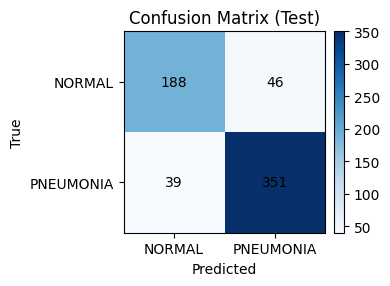

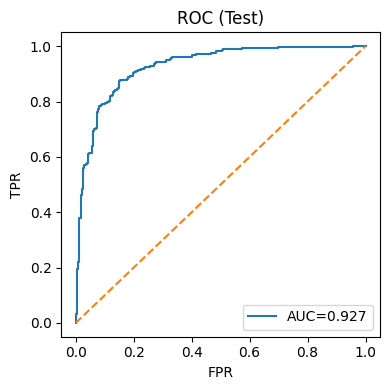

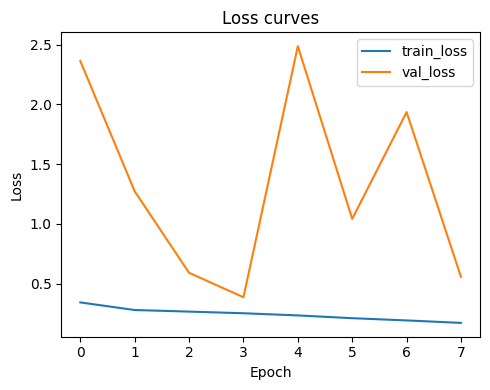

In [22]:
# ======================
# 6) Visualisations & fichiers
# ======================
# Matrice de confusion
cm = confusion_matrix(yt, yt_hat)
fig, ax = plt.subplots(figsize=(4,4))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Confusion Matrix (Test)")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i,j], ha="center", va="center")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUT_DIR/"confusion_matrix.png", dpi=150)
plt.show()

# ROC
fpr, tpr, _ = roc_curve(yt, yt_prob)
plt.figure(figsize=(4,4))
plt.plot(fpr, tpr, label=f"AUC={test_auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (Test)")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR/"roc_curve.png", dpi=150)
plt.show()

# Courbes de perte (train/val)
plt.figure(figsize=(5,4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["val_loss"], label="val_loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss curves")
plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR/"loss_curves.png", dpi=150)
plt.show()

In [23]:
# ======================
# 7) Logging CSV
# ======================
row = {
    "model":"BaselineCNN",
    "img_size":"224",
    "batch":BATCH,
    "epochs_ran":len(history["train_loss"]),
    "train_time_s":round(train_time,2),
    "val_best_auc":round(best_val_auc,4),
    "test_acc":round(test_acc,4),
    "test_f1":round(test_f1,4),
    "test_auc":round(test_auc,4),
    "seed":SEED
}
write_header = not METRICS_CSV.exists()
with open(METRICS_CSV, "a", newline="") as f:
    w = csv.DictWriter(f, fieldnames=row.keys())
    if write_header: w.writeheader()
    w.writerow(row)

print("Saved:", METRICS_CSV, ",", OUT_DIR/"confusion_matrix.png", ",", OUT_DIR/"roc_curve.png")
print("Best model:", best_path)


Saved: results\metrics.csv , results\confusion_matrix.png , results\roc_curve.png
Best model: models\baseline_cnn_best.pt


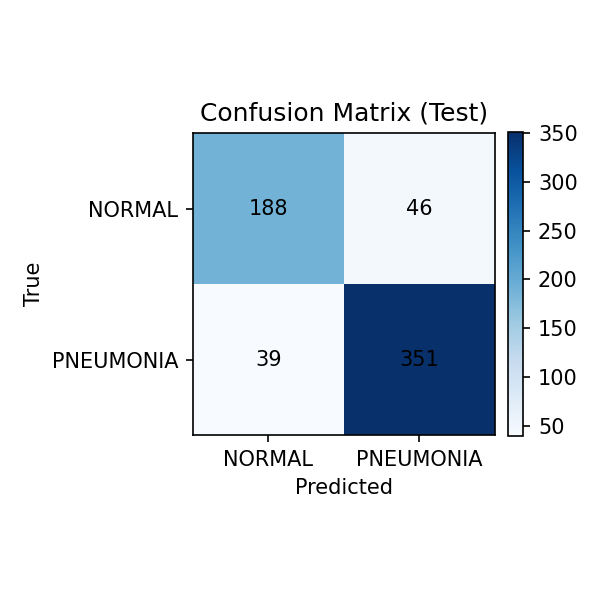

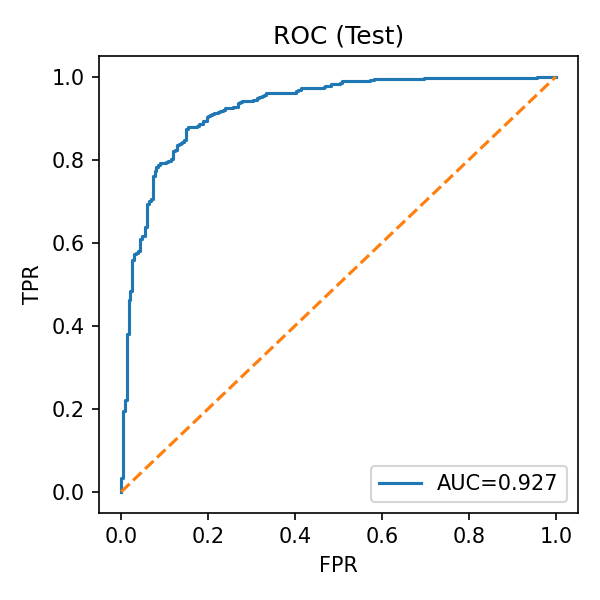

In [25]:
from IPython.display import Image, display
display(Image("results/confusion_matrix.png"))
display(Image("results/roc_curve.png"))

In [26]:
# Charger ResNet18 pré-entraîné
#model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model = models.resnet18()
weights_path = "models_pretrained/resnet18-f37072fd.pth"
state_dict = torch.load(weights_path)
model.load_state_dict(state_dict)

# Adapter la dernière couche pour 2 classes
num_features = model.fc.in_features
#NUM_CLASSES = 2
model.fc = nn.Linear(num_features, NUM_CLASSES)

# Option : geler les features, ne fine-tuner que la dernière couche
for param in model.parameters():
    param.requires_grad = False
model.fc.requires_grad = True

# Envoyer sur GPU
model = model.to(DEVICE)

# Définir loss et optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)  # même que baseline
optimizer = optim.Adam(model.fc.parameters(), lr=1e-4)  # petit LR


In [27]:
# ======================
# RESNET18 — TRAIN/EVAL/COMPARE (fix)
# ======================

# --------- Phase 1: Feature extractor (geler le backbone, entraîner la tête) ----------
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_features = resnet.fc.in_features
resnet.fc = nn.Linear(num_features, NUM_CLASSES)

# 1) Geler tout
for p in resnet.parameters():
    p.requires_grad = False
# 2) Dé-geler uniquement la tête (fc) -> IMPORTANT: sur les paramètres !
for p in resnet.fc.parameters():
    p.requires_grad = True

# 3) S'assurer que run_epoch utilise ce modèle
model = resnet.to(DEVICE)

# Loss / Optimiseur / Scheduler
criterion = nn.CrossEntropyLoss(weight=class_weights)
# Ne passer que les paramètres entraînables (robuste et évite les surprises)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

EPOCHS = 10
best_val_auc = -1
best_path = MODEL_DIR/"resnet18_head_best.pt"
history_res = {"train_loss":[], "val_loss":[], "val_auc":[]}

t0 = time.time()
for epoch in range(1, EPOCHS+1):
    # run_epoch doit utiliser la variable globale 'model' (qui pointe maintenant vers resnet)
    tr_loss, tr_acc, tr_f1, tr_auc, *_ = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc, val_f1, val_auc, yv, yv_hat, yv_prob = run_epoch(val_loader, train_mode=False)

    scheduler.step(val_loss)
    history_res["train_loss"].append(tr_loss); history_res["val_loss"].append(val_loss); history_res["val_auc"].append(val_auc)

    print(f"[ResNet18-Head {epoch:02d}/{EPOCHS}] "
          f"train_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.3f} "
          f"| val_f1={val_f1:.3f} | val_auc={val_auc:.3f}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({"state_dict": model.state_dict(), "classes": CLASSES, "seed": SEED}, best_path)
        print("  ↳ Saved new best:", best_path, "AUC:", round(best_val_auc,4))

train_time_head = round(time.time() - t0, 2)
print("Phase 1 done. Best Val AUC:", round(best_val_auc,4), " | Time(s):", train_time_head)


[ResNet18-Head 01/10] train_loss=0.5521 | val_loss=0.4291 | val_acc=0.875 | val_f1=0.873 | val_auc=0.906
  ↳ Saved new best: models\resnet18_head_best.pt AUC: 0.9062
[ResNet18-Head 02/10] train_loss=0.3987 | val_loss=0.3291 | val_acc=0.875 | val_f1=0.873 | val_auc=0.922
  ↳ Saved new best: models\resnet18_head_best.pt AUC: 0.9219
[ResNet18-Head 03/10] train_loss=0.3234 | val_loss=0.3061 | val_acc=0.938 | val_f1=0.937 | val_auc=0.922
[ResNet18-Head 04/10] train_loss=0.2866 | val_loss=0.2629 | val_acc=0.938 | val_f1=0.937 | val_auc=0.938
  ↳ Saved new best: models\resnet18_head_best.pt AUC: 0.9375
[ResNet18-Head 05/10] train_loss=0.2650 | val_loss=0.2613 | val_acc=0.938 | val_f1=0.937 | val_auc=0.938
[ResNet18-Head 06/10] train_loss=0.2529 | val_loss=0.2337 | val_acc=0.938 | val_f1=0.937 | val_auc=0.953
  ↳ Saved new best: models\resnet18_head_best.pt AUC: 0.9531
[ResNet18-Head 07/10] train_loss=0.2421 | val_loss=0.2353 | val_acc=0.938 | val_f1=0.937 | val_auc=0.953
[ResNet18-Head 08/10]

In [28]:
# --------- (Optionnel) Phase 2: Fine-tuning partiel du backbone ----------
DO_FINETUNE = True  # mets False si tu veux sauter cette étape
if DO_FINETUNE:
    # Charger le meilleur de la phase 1
    ckpt = torch.load(best_path, map_location=DEVICE)
    resnet.load_state_dict(ckpt["state_dict"])

    # Dé-geler le bloc final (layer4) + la tête
    for p in resnet.parameters():
        p.requires_grad = False
    for p in resnet.layer4.parameters():
        p.requires_grad = True
    for p in resnet.fc.parameters():
        p.requires_grad = True

    optimizer = optim.Adam(filter(lambda p: p.requires_grad, resnet.parameters()), lr=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

    best_val_auc_ft = best_val_auc
    best_path_ft = MODEL_DIR/"resnet18_finetune_best.pt"
    EPOCHS_FT = 6
    for epoch in range(1, EPOCHS_FT+1):
        tr_loss, tr_acc, tr_f1, tr_auc, *_ = run_epoch(train_loader, train_mode=True)
        val_loss, val_acc, val_f1, val_auc, yv, yv_hat, yv_prob = run_epoch(val_loader, train_mode=False)

        scheduler.step(val_loss)
        history_res["train_loss"].append(tr_loss); history_res["val_loss"].append(val_loss); history_res["val_auc"].append(val_auc)
        print(f"[ResNet18-FT {epoch:02d}/{EPOCHS_FT}] train_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.3f} | val_f1={val_f1:.3f} | val_auc={val_auc:.3f}")

        if val_auc > best_val_auc_ft:
            best_val_auc_ft = val_auc
            torch.save({"state_dict": resnet.state_dict(), "classes": CLASSES, "seed": SEED}, best_path_ft)
            print("  ↳ Saved new best (FT):", best_path_ft, "AUC:", round(best_val_auc_ft,4))

    # Choisir le meilleur checkpoint entre Phase 1 et FT
    if best_val_auc_ft > best_val_auc:
        final_ckpt_path = best_path_ft
        best_val_auc = best_val_auc_ft
    else:
        final_ckpt_path = best_path
else:
    final_ckpt_path = best_path

print("Chosen best checkpoint:", final_ckpt_path)
    

[ResNet18-FT 01/6] train_loss=0.1640 | val_loss=0.2421 | val_acc=0.938 | val_f1=0.937 | val_auc=0.984
  ↳ Saved new best (FT): models\resnet18_finetune_best.pt AUC: 0.9844
[ResNet18-FT 02/6] train_loss=0.1142 | val_loss=0.2772 | val_acc=0.875 | val_f1=0.873 | val_auc=1.000
  ↳ Saved new best (FT): models\resnet18_finetune_best.pt AUC: 1.0
[ResNet18-FT 03/6] train_loss=0.0875 | val_loss=0.1872 | val_acc=1.000 | val_f1=1.000 | val_auc=1.000
[ResNet18-FT 04/6] train_loss=0.0744 | val_loss=0.2177 | val_acc=1.000 | val_f1=1.000 | val_auc=1.000
[ResNet18-FT 05/6] train_loss=0.0673 | val_loss=0.6259 | val_acc=0.750 | val_f1=0.733 | val_auc=1.000
[ResNet18-FT 06/6] train_loss=0.0591 | val_loss=0.2912 | val_acc=0.875 | val_f1=0.873 | val_auc=1.000
Chosen best checkpoint: models\resnet18_finetune_best.pt


In [29]:
# --------- Évaluation finale sur TEST ----------
ckpt = torch.load(final_ckpt_path, map_location=DEVICE)
resnet.load_state_dict(ckpt["state_dict"])
def eval_on(loader, model):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    total_loss = 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            total_loss += loss.item() * xb.size(0)
            p = out.argmax(1)
            pr = torch.softmax(out, dim=1)[:,1]
            y_true.append(yb.detach().cpu().numpy())
            y_pred.append(p.detach().cpu().numpy())
            y_prob.append(pr.detach().cpu().numpy())
    y_true = np.concatenate(y_true); y_pred = np.concatenate(y_pred); y_prob = np.concatenate(y_prob)
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="weighted")
    auc = roc_auc_score(y_true, y_prob)
    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, acc, f1, auc, y_true, y_pred, y_prob

test_loss, test_acc, test_f1, test_auc, yt, yt_hat, yt_prob = eval_on(test_loader, resnet)
print(f"[ResNet18] TEST — loss={test_loss:.4f} | acc={test_acc:.3f} | f1={test_f1:.3f} | auc={test_auc:.3f}")


[ResNet18] TEST — loss=0.3158 | acc=0.880 | f1=0.875 | auc=0.959


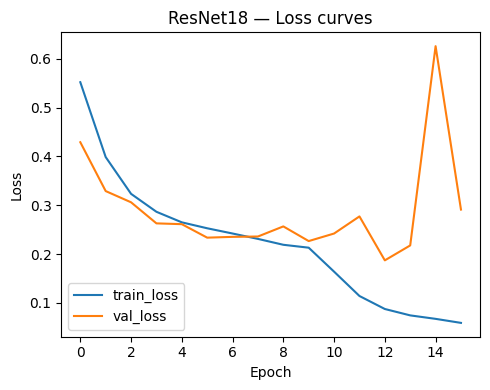

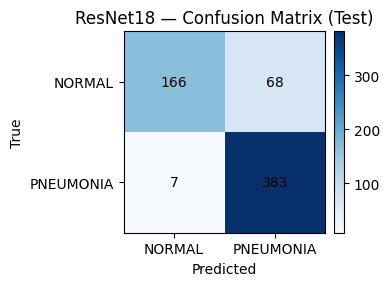

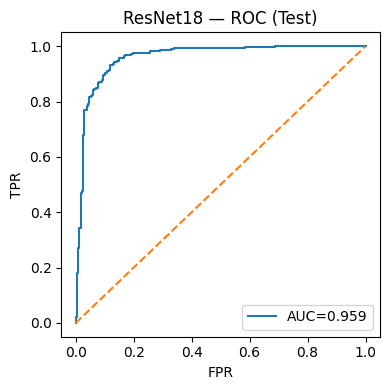

In [30]:
# --------- Visualisations (loss curves, confusion matrix, ROC) ----------
# Courbes de perte (train/val) cumulées des 2 phases
plt.figure(figsize=(5,4))
plt.plot(history_res["train_loss"], label="train_loss")
plt.plot(history_res["val_loss"], label="val_loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("ResNet18 — Loss curves")
plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR/"resnet18_loss_curves.png", dpi=150)

# Matrice de confusion
cm = confusion_matrix(yt, yt_hat)
fig, ax = plt.subplots(figsize=(4,4))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("ResNet18 — Confusion Matrix (Test)")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i,j], ha="center", va="center")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUT_DIR/"resnet18_confusion_matrix.png", dpi=150)

# ROC
fpr, tpr, _ = roc_curve(yt, yt_prob)
plt.figure(figsize=(4,4))
plt.plot(fpr, tpr, label=f"AUC={test_auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ResNet18 — ROC (Test)")
plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR/"resnet18_roc_curve.png", dpi=150)


In [31]:
# --------- Logging CSV (comparaison avec baseline)
row = {
    "model":"ResNet18(Head{}{})".format(
        "" if not DO_FINETUNE else "+FT",
        ""
    ),
    "img_size":"224",
    "batch":train_loader.batch_size,
    "epochs_ran":len(history_res["train_loss"]),
    "train_time_s":train_time_head,  # (NB: n’inclut pas le FT pour rester simple)
    "val_best_auc":round(best_val_auc,4),
    "test_acc":round(test_acc,4),
    "test_f1":round(test_f1,4),
    "test_auc":round(test_auc,4),
    "seed":SEED
}
write_header = not METRICS_CSV.exists()
with open(METRICS_CSV, "a", newline="") as f:
    w = csv.DictWriter(f, fieldnames=row.keys())
    if write_header: w.writeheader()
    w.writerow(row)

print("Saved:",
      OUT_DIR/"resnet18_loss_curves.png",
      OUT_DIR/"resnet18_confusion_matrix.png",
      OUT_DIR/"resnet18_roc_curve.png")
print("Metrics appended to:", METRICS_CSV)

Saved: results\resnet18_loss_curves.png results\resnet18_confusion_matrix.png results\resnet18_roc_curve.png
Metrics appended to: results\metrics.csv


C:\Users\moham\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\nn\modules\module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


Saved: results\resnet18_gradcam_examples.png


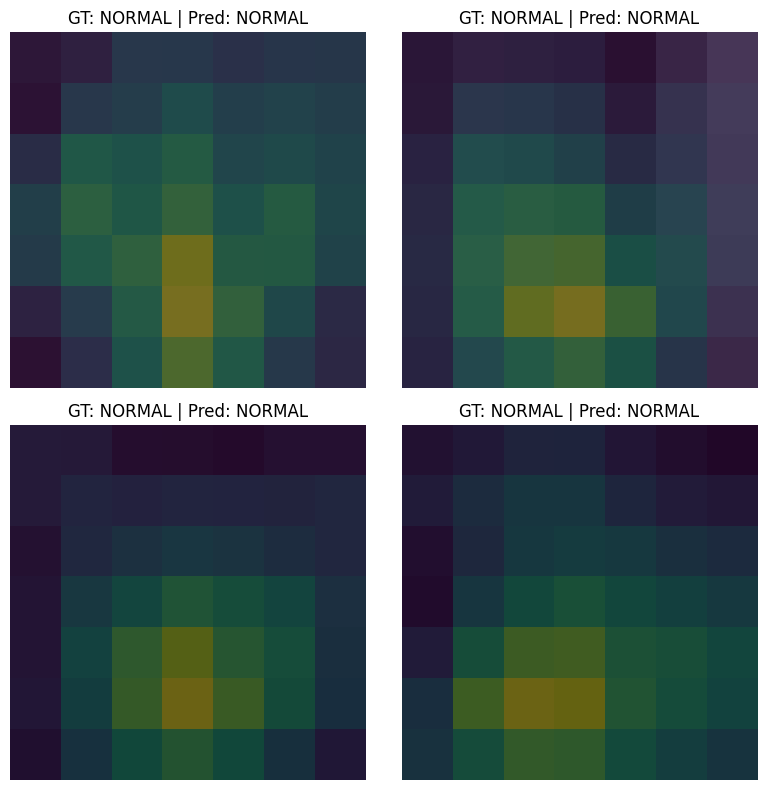

In [32]:
# --------- Grad-CAM (rapide) sur quelques images test ----------
# Utilise le dernier bloc conv (layer4[-1]) pour des heatmaps simples
def grad_cam_single(model, image_tensor, target_layer):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(DEVICE)
    activations = {}
    gradients = {}

    def fwd_hook(m, i, o): activations['value'] = o
    def bwd_hook(m, gi, go): gradients['value'] = go[0]

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_backward_hook(bwd_hook)

    out = model(image_tensor)
    class_idx = out.argmax(1).item()
    score = out[0, class_idx]
    model.zero_grad()
    score.backward()

    acts = activations['value'].detach()[0]          # (C,H,W)
    grads = gradients['value'].detach()[0]           # (C,H,W)
    weights = grads.mean(dim=(1,2), keepdim=True)    # (C,1,1)
    cam = (acts * weights).sum(0).cpu().numpy()      # (H,W)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    h1.remove(); h2.remove()
    return cam, class_idx


# Afficher 4 heatmaps Grad-CAM
import random
to_pil = None
try:
    from torchvision.transforms.functional import to_pil_image as to_pil
except:
    pass

def denorm(x):
    # annule la normalisation ImageNet pour l'affichage
    mean = np.array([0.485,0.456,0.406]).reshape(3,1,1)
    std  = np.array([0.229,0.224,0.225]).reshape(3,1,1)
    x = x.cpu().numpy()
    x = (x * std + mean).clip(0,1)
    return x

layer_target = resnet.layer4[-1]
samples = []
for xb, yb in test_loader:
    for i in range(min(2, xb.size(0))):
        samples.append( (xb[i], yb[i].item()) )
    if len(samples) >= 4: break

plt.figure(figsize=(8,8))
for idx, (img, lab) in enumerate(samples, 1):
    cam, pred = grad_cam_single(resnet, img, layer_target)
    img_dn = denorm(img)
    plt.subplot(2,2,idx)
    # superposer cam en pseudo-couleur
    plt.imshow(np.transpose(img_dn, (1,2,0)))
    plt.imshow(cam, alpha=0.4)  # heatmap translucide
    plt.title(f"GT: {CLASSES[lab]} | Pred: {CLASSES[pred]}")
    plt.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR/"resnet18_gradcam_examples.png", dpi=150)
print("Saved:", OUT_DIR/"resnet18_gradcam_examples.png")


In [33]:
# ============================================
# EXPERIMENT RUNNER: Multi-backbone, Phase A+B
# ============================================

# ------- Dossiers de sortie
OUT_DIR = Path("results"); OUT_DIR.mkdir(exist_ok=True, parents=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True, parents=True)
METRICS_CSV = OUT_DIR/"metrics.csv"

# ------- Utilitaires
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def freeze_all(m):
    for p in m.parameters(): p.requires_grad = False

def unfreeze_layers(layers_or_module):
    # layers_or_module : liste de modules OU un module unique
    if isinstance(layers_or_module, (list, tuple)):
        for block in layers_or_module:
            for p in block.parameters(): p.requires_grad = True
    else:
        for p in layers_or_module.parameters(): p.requires_grad = True

def make_model(name, num_classes=2, pretrained=True):
    """Retourne (model, head_params_fn, ft_layers, last_conv_for_cam, id_str)"""
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = m.fc.in_features
        m.fc = nn.Linear(in_f, num_classes)
        head_params_fn = lambda: m.fc.parameters()
        ft_layers = [m.layer4, m.fc]
        last_conv = m.layer4[-1]
        tag = "resnet18"
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = m.fc.in_features
        m.fc = nn.Linear(in_f, num_classes)
        head_params_fn = lambda: m.fc.parameters()
        ft_layers = [m.layer4, m.fc]
        last_conv = m.layer4[-1]
        tag = "resnet50"
    elif name == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = m.classifier.in_features
        m.classifier = nn.Linear(in_f, num_classes)
        head_params_fn = lambda: m.classifier.parameters()
        ft_layers = [m.features, m.classifier]  # souvent on fine-tune tout
        last_conv = m.features[-1]
        tag = "densenet121"
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = m.classifier[1].in_features
        m.classifier[1] = nn.Linear(in_f, num_classes)
        head_params_fn = lambda: m.classifier.parameters()
        ft_layers = [m.features[-1], m.classifier]
        last_conv = m.features[-1]
        tag = "efficientnet_b0"
    elif name == "mobilenet_v3_large":
        m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None)
        in_f = m.classifier[-1].in_features
        m.classifier[-1] = nn.Linear(in_f, num_classes)
        head_params_fn = lambda: m.classifier.parameters()
        ft_layers = [m.features[-1], m.classifier]
        last_conv = m.features[-1][-1] if hasattr(m.features[-1], '__getitem__') else m.features[-1]
        tag = "mobilenet_v3_large"
    else:
        raise ValueError("Unknown model name:", name)
    return m, head_params_fn, ft_layers, last_conv, tag

In [34]:
# ------- Entraînement/éval d'une epoch (avec AMP)
def run_epoch(loader, model, criterion, optimizer=None, device="cuda"):
    train_mode = optimizer is not None
    model.train(mode=train_mode)
    total_loss = 0.0
    y_true, y_pred, y_prob = [], [], []
    scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        with torch.cuda.amp.autocast(enabled=(device!="cpu")):
            out = model(xb)
            loss = criterion(out, yb)
        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
        total_loss += loss.item() * xb.size(0)
        prob1 = torch.softmax(out, dim=1)[:,1].detach().cpu().numpy()
        pred = out.argmax(1).detach().cpu().numpy()
        y_true.append(yb.detach().cpu().numpy())
        y_pred.append(pred)
        y_prob.append(prob1)
    y_true = np.concatenate(y_true); y_pred = np.concatenate(y_pred); y_prob = np.concatenate(y_prob)
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="weighted")
    try:
        auc = roc_auc_score(y_true, y_prob)
    except:
        auc = np.nan
    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, acc, f1, auc, y_true, y_pred, y_prob

In [35]:
# ------- Plot helpers
def plot_losses(hist, out_path, title="Loss curves"):
    plt.figure(figsize=(5,4))
    plt.plot(hist["train_loss"], label="train_loss")
    plt.plot(hist["val_loss"], label="val_loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.savefig(out_path, dpi=150); plt.close()

def plot_cm(y_true, y_pred, classes, out_path, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(4,4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(classes); ax.set_yticklabels(classes)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i,j], ha="center", va="center")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.savefig(out_path, dpi=150); plt.close()

def plot_roc(y_true, y_prob, out_path, title="ROC"):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    plt.figure(figsize=(4,4))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0,1],[0,1], linestyle="--")
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.savefig(out_path, dpi=150); plt.close()


In [47]:

# ------- Grad-CAM simple with a new parameters device
def grad_cam_single(model, image_tensor, target_layer, device="cuda"):
    model.eval()
    x = image_tensor.unsqueeze(0).to(device)
    activations, gradients = {}, {}
    def fwd_hook(m, i, o): activations['v'] = o
    def bwd_hook(m, gi, go): gradients['v'] = go[0]
    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_backward_hook(bwd_hook)
    out = model(x)
    cls = out.argmax(1).item()
    score = out[0, cls]
    model.zero_grad(); score.backward()
    acts = activations['v'].detach()[0]        # (C,H,W)
    grads = gradients['v'].detach()[0]         # (C,H,W)
    weights = grads.mean(dim=(1,2), keepdim=True)
    cam = (acts * weights).sum(0).cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    h1.remove(); h2.remove()
    return cam, cls

def denorm_img(x):
    mean = np.array([0.485,0.456,0.406]).reshape(3,1,1)
    std  = np.array([0.229,0.224,0.225]).reshape(3,1,1)
    x = x.cpu().numpy()
    x = (x * std + mean).clip(0,1)
    return np.transpose(x, (1,2,0))

def save_gradcam_grid(model, layer, loader, classes, out_path, device="cuda", n=4):
    # prend n images du test et sauvegarde une grille CAM
    samples = []
    for xb, yb in loader:
        for i in range(min(n, xb.size(0))):
            samples.append( (xb[i], yb[i].item()) )
        break
    plt.figure(figsize=(8,8))
    for i, (img, lab) in enumerate(samples[:n], 1):
        cam, pred = grad_cam_single(model, img, layer, device=device)
        base = denorm_img(img)
        plt.subplot(int(np.ceil(n/2)), 2, i)
        plt.imshow(base); plt.imshow(cam, alpha=0.4)
        plt.title(f"GT: {classes[lab]} | Pred: {classes[pred]}")
        plt.axis("off")
    plt.tight_layout(); plt.savefig(out_path, dpi=150); plt.close()


In [37]:
def unfreeze_layers(layers_or_params):
    """
    Accepte :
      - un module (ayant .parameters())
      - une liste/tuple de modules
      - un itérable de paramètres (ex: head_params_fn())
    """
    # Cas 1: liste/tuple de modules
    if isinstance(layers_or_params, (list, tuple)):
        for block in layers_or_params:
            for p in block.parameters():
                p.requires_grad = True
        return

    # Cas 2: module unique
    if hasattr(layers_or_params, "parameters"):
        for p in layers_or_params.parameters():
            p.requires_grad = True
        return

    # Cas 3: itérable de paramètres (generator, list of params, etc.)
    try:
        for p in layers_or_params:
            p.requires_grad = True
        return
    except TypeError:
        raise TypeError("unfreeze_layers: objet non supporté (ni module, ni iterable de paramètres)")


In [48]:
def train_eval_compare(backbone_name,
                       train_loader, val_loader, test_loader,
                       classes, num_classes, class_weights,
                       device="cuda",
                       epochs_A=8, epochs_B=5,
                       lr_A=1e-4, lr_B=1e-5,
                       patience=2):
    set_seed(SEED if 'SEED' in globals() else 42)

    model, head_params_fn, ft_layers, last_conv, tag = make_model(backbone_name, num_classes=num_classes, pretrained=True)
    model = model.to(device)

    # ----- Phase A
    freeze_all(model)
    unfreeze_layers(head_params_fn())
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr_A)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience)

    hist = {"train_loss": [], "val_loss": [], "val_auc": []}
    best_auc_A, best_path_A = -1, MODEL_DIR / f"{tag}_A_best.pt"
    t0 = time.time()
    for ep in range(1, epochs_A + 1):
        tr_loss, *_ = run_epoch(train_loader, model, criterion, optimizer, device)
        val_loss, val_acc, val_f1, val_auc, *_ = run_epoch(val_loader, model, criterion, optimizer=None, device=device)
        scheduler.step(val_loss)
        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(val_loss)
        hist["val_auc"].append(val_auc)
        print(f"[{tag} A {ep:02d}/{epochs_A}] tr_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.3f} | val_f1={val_f1:.3f} | val_auc={val_auc:.3f}")
        if val_auc > best_auc_A:
            best_auc_A = val_auc
            torch.save({"state_dict": model.state_dict(), "classes": classes}, best_path_A)
    time_A = round(time.time() - t0, 2)

    # Recharger A
    model.load_state_dict(torch.load(best_path_A, map_location=device)["state_dict"])

    # ----- Phase B
    freeze_all(model)
    unfreeze_layers(ft_layers)
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr_B)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience)

    best_auc_B, best_path_B = -1, MODEL_DIR / f"{tag}_AB_best.pt"
    t0 = time.time()
    for ep in range(1, epochs_B + 1):
        tr_loss, *_ = run_epoch(train_loader, model, criterion, optimizer, device)
        val_loss, val_acc, val_f1, val_auc, *_ = run_epoch(val_loader, model, criterion, optimizer=None, device=device)
        scheduler.step(val_loss)
        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(val_loss)
        hist["val_auc"].append(val_auc)
        print(f"[{tag} B {ep:02d}/{epochs_B}] tr_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.3f} | val_f1={val_f1:.3f} | val_auc={val_auc:.3f}")
        if val_auc > best_auc_B:
            best_auc_B = val_auc
            torch.save({"state_dict": model.state_dict(), "classes": classes}, best_path_B)

    # Sauvegarde du dernier modèle B même s’il n’est pas meilleur
    if not best_path_B.exists():
        torch.save({"state_dict": model.state_dict(), "classes": classes}, best_path_B)

    time_B = round(time.time() - t0, 2)

    # Chargement du meilleur modèle global
    final_ckpt_path = best_path_B if best_auc_B >= best_auc_A else best_path_A
    model.load_state_dict(torch.load(final_ckpt_path, map_location=device)["state_dict"])

    # ----- Test
    test_loss, test_acc, test_f1, test_auc, yt, yt_hat, yt_prob = run_epoch(test_loader, model, criterion, optimizer=None, device=device)
    print(f"[{tag}] TEST — loss={test_loss:.4f} | acc={test_acc:.3f} | f1={test_f1:.3f} | auc={test_auc:.3f}")

    # ----- Visus
    plot_losses(hist, OUT_DIR / f"{tag}_loss_curves.png", title=f"{tag} — Loss curves")
    plot_cm(yt, yt_hat, classes, OUT_DIR / f"{tag}_confusion_matrix.png", title=f"{tag} — Confusion Matrix (Test)")
    plot_roc(yt, yt_prob, OUT_DIR / f"{tag}_roc_curve.png", title=f"{tag} — ROC (Test)")
    save_gradcam_grid(model, last_conv, test_loader, classes, OUT_DIR / f"{tag}_gradcam_examples.png", device=device, n=4)

    # ----- Logging
    row = {
        "model": tag,
        "phase": "A+B",
        "img_size": "224",
        "batch": train_loader.batch_size,
        "epochs_ran": len(hist["train_loss"]),
        "val_best_auc": round(max(best_auc_A, best_auc_B), 4),
        "test_acc": round(test_acc, 4),
        "test_f1": round(test_f1, 4),
        "test_auc": round(test_auc, 4),
        "train_time_s": time_A + time_B,
        "seed": SEED if 'SEED' in globals() else 42,
        "checkpoint": str(final_ckpt_path)
    }
    write_header = not METRICS_CSV.exists()
    with open(METRICS_CSV, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=row.keys())
        if write_header: w.writeheader()
        w.writerow(row)

    return {
        "tag": tag,
        "val_best_auc": max(best_auc_A, best_auc_B),
        "test_metrics": {"loss": test_loss, "acc": test_acc, "f1": test_f1, "auc": test_auc},
        "ckpt": str(final_ckpt_path)
    }


In [49]:
# =======================
# Lancer plusieurs modèles
# =======================
backbones = ["resnet18", "resnet50", "densenet121", "efficientnet_b0", "mobilenet_v3_large"]

results = []
for name in backbones:
    print("\n" + "="*70)
    print(f"▶ Running {name}")
    print("="*70)
    out = train_eval_compare(
        backbone_name=name,
        train_loader=train_loader, val_loader=val_loader, test_loader=test_loader,
        classes=CLASSES, num_classes=NUM_CLASSES, class_weights=class_weights,
        device=str(DEVICE),  # "cuda" or "cpu"
        epochs_A=8, epochs_B=5, lr_A=1e-4, lr_B=1e-5, patience=2
    )
    results.append(out)

print("\nSUMMARY (by val_best_auc):")
for r in sorted(results, key=lambda x: x["val_best_auc"], reverse=True):
    tm = r["test_metrics"]
    print(f"- {r['tag']:>18} | Val AUC={r['val_best_auc']:.3f} | Test AUC={tm['auc']:.3f} | Test F1={tm['f1']:.3f} | ckpt={r['ckpt']}")


▶ Running resnet18


C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu")):
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu"

[resnet18 A 01/8] tr_loss=0.5060 | val_loss=0.3721 | val_acc=0.875 | val_f1=0.873 | val_auc=0.969


C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu")):
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu"

[resnet18 A 02/8] tr_loss=0.3629 | val_loss=0.3086 | val_acc=0.938 | val_f1=0.937 | val_auc=0.969


...

[resnet50 A 01/8] tr_loss=0.4780 | val_loss=0.4638 | val_acc=0.875 | val_f1=0.875 | val_auc=0.906


C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu")):
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu"

[resnet50 A 02/8] tr_loss=0.3166 | val_loss=0.3819 | val_acc=0.875 | val_f1=0.875 | val_auc=0.922


C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device!="cpu"))
C:\Users\moham\AppData\Local\Temp\ipykernel_8848\2128035181.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device!="cpu")):


KeyboardInterrupt: 

In [ ]:
df_results = pd.DataFrame(results)  # results est la liste des outputs de `train_eval_compare`
df_results = df_results[["tag", "val_best_auc", "test_metrics"]]
df_results["test_auc"] = df_results["test_metrics"].apply(lambda x: x["auc"])
df_results["test_f1"] = df_results["test_metrics"].apply(lambda x: x["f1"])
df_results["test_acc"] = df_results["test_metrics"].apply(lambda x: x["acc"])
df_results = df_results.drop(columns=["test_metrics"])

print(df_results.sort_values("val_best_auc", ascending=False))


KeyError: "None of [Index(['tag', 'val_best_auc', 'test_metrics'], dtype='object')] are in the [columns]"

In [ ]:
results_df = pd.DataFrame(results)

Saved: results\comparison_roc.png


C:\Users\moham\AppData\Local\Temp\ipykernel_8848\626862157.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


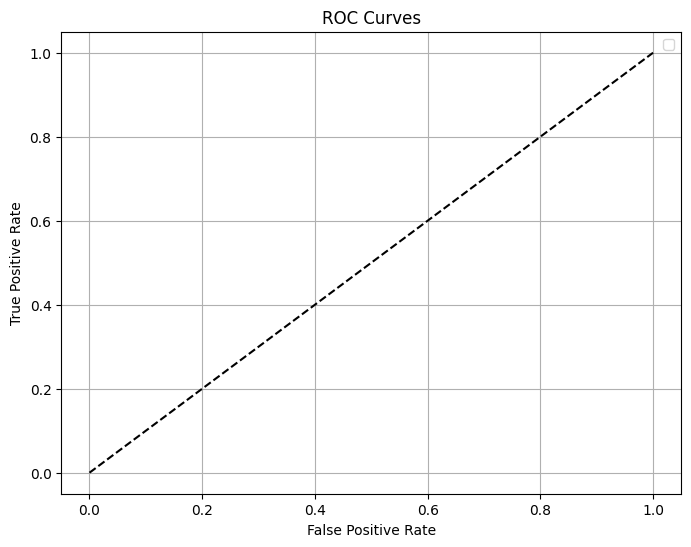

In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))
for r in results:
    y_true = r["y_true"]
    y_prob = r["y_prob"]
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{r["tag"]} (AUC={roc_auc:.3f})')

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid()
plt.savefig(OUT_DIR/"comparison_roc.png", dpi=150)
print("Saved:", OUT_DIR/"comparison_roc.png")
